# 07 · Resultados

Reúne os resultados da modelagem para responder à pergunta do projeto: **os hábitos antes de dormir permitem prever a categoria de débito de sono?** As métricas vêm de `reports/metrics/resultados.csv`, gerado na etapa 6, e os modelos analisados em detalhe são recriados a partir dos hiperparâmetros salvos nele, sem repetir a busca.

In [1]:
%load_ext autoreload
%autoreload 2

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.inspection import permutation_importance
from sklearn.metrics import classification_report
from sklearn.tree import export_text

from scroll_sono.config import FEATURE_SETS, FIGURES_DIR, ORDINAL_COLS, RANDOM_STATE, RESULTS_PATH, TARGET, TARGET_CLASSES
from scroll_sono.data import load_test, load_train
from scroll_sono.evaluation import METRIC_NAMES, SCENARIO_COLORS, SEQUENTIAL, ignore_bin_warnings, plot_confusion_matrix
from scroll_sono.models import MODEL_NAMES, build_pipeline

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

In [2]:
# Estilo dos gráficos (o mesmo da EDA)
SUPERFICIE, TEXTO, TEXTO_SECUNDARIO, GRADE = "#fcfcfb", "#0b0b0b", "#52514e", "#e8e7e3"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "text.color": TEXTO, "axes.labelcolor": TEXTO_SECUNDARIO, "axes.edgecolor": "#c3c2b7",
    "xtick.color": TEXTO_SECUNDARIO, "ytick.color": TEXTO_SECUNDARIO,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRADE, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titlelocation": "left", "figure.titlesize": 12,
    "font.size": 9, "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})


def salvar(fig, nome: str) -> None:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(FIGURES_DIR / f"{nome}.png")

In [3]:
resultados = pd.read_csv(RESULTS_PATH)
train, test = load_train(), load_test()
X_train, y_train = train.drop(columns=TARGET), train[TARGET]
X_test, y_test = test.drop(columns=TARGET), test[TARGET]
print(f"Resultados: {len(resultados)} linhas (cenário × modelo)")

Resultados: 10 linhas (cenário × modelo)


## 1. Comparação dos modelos

Métricas no conjunto de teste, com o F1 macro médio da validação cruzada ao lado. O F1 macro foi o critério de escolha dos hiperparâmetros, porque dá o mesmo peso às quatro classes.

In [4]:
colunas = {"cv_f1_macro": "F1 macro (validação cruzada)", "teste_acuracia": "Acurácia",
           "teste_acuracia_balanceada": "Acurácia balanceada", "teste_f1_macro": "F1 macro"}
tabela = resultados.set_index(["cenário", "modelo"])[list(colunas)].rename(columns=colunas).round(3)
tabela

F1 macro (validação cruzada)  Acurácia  Acurácia balanceada  F1 macro
cenário        modelo                                                                                       
comportamental Baseline                                       0.172     0.525                0.250     0.172
               KNN                                            0.578     0.648                0.533     0.563
               Naive Bayes Gaussiano                          0.613     0.701                0.625     0.637
               Naive Bayes Categórico                         0.575     0.690                0.553     0.594
               Árvore de Decisão                              0.646     0.713                0.623     0.646
completo       Baseline                                       0.172     0.525                0.250     0.172
               KNN                                            0.800     0.830                0.770     0.795
               Naive Bayes Gaussiano                          0.865     0.870                0.899     0.859
               Naive Bayes Categórico                         0.934     0.956                0.961     0.936
               Árvore de Decisão                              1.000     1.000                1.000     1.000

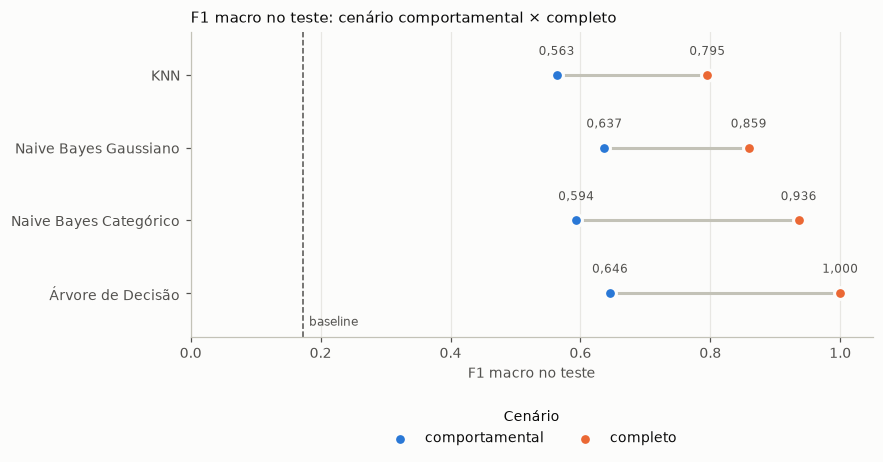

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.6))
modelos = [MODEL_NAMES[nome] for nome in MODEL_NAMES if nome != "baseline"]
y = np.arange(len(modelos))
f1 = resultados.pivot(index="modelo", columns="cenário", values="teste_f1_macro").loc[modelos]
baseline = resultados.loc[resultados["algoritmo"] == "baseline", "teste_f1_macro"].iloc[0]

ax.hlines(y, f1["comportamental"], f1["completo"], color="#c3c2b7", lw=2, zorder=1)
for cenario in ["comportamental", "completo"]:
    ax.scatter(f1[cenario], y, s=60, color=SCENARIO_COLORS[cenario], edgecolor=SUPERFICIE, lw=2,
               label=cenario, zorder=2)
    for yi, valor in zip(y, f1[cenario]):
        ax.text(valor, yi - 0.28, f"{valor:.3f}".replace(".", ","), ha="center", fontsize=8,
                color=TEXTO_SECUNDARIO)
ax.axvline(baseline, color=TEXTO_SECUNDARIO, lw=1, ls="--")
ax.text(baseline + 0.01, len(modelos) - 0.55, "baseline", fontsize=8, color=TEXTO_SECUNDARIO)
ax.set_yticks(y, modelos)
ax.set_ylim(len(modelos) - 0.4, -0.6)
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1 macro no teste")
ax.grid(axis="y", visible=False)
ax.legend(title="Cenário", loc="upper center", bbox_to_anchor=(0.5, -0.2), ncols=2, frameon=False)
ax.set_title("F1 macro no teste: cenário comportamental × completo")
salvar(fig, "07_comparacao_cenarios")

**Resultado:**

- **Cenário comportamental (principal):** a árvore de decisão (F1 macro de 0,646) e o Naive Bayes Gaussiano (0,637) são os melhores, com desempenhos próximos no teste. Na validação cruzada, a árvore ficou à frente (0,646 × 0,613), mas são estimativas de um único experimento, sem teste estatístico. Os dois acertam cerca de 70% dos registros (71,3% e 70,1%), contra 52,5% do baseline, que só prevê `Moderate Debt`.
- **KNN e Naive Bayes Categórico** ficam atrás (0,563 e 0,594). Uma hipótese para o KNN é que as distâncias misturam atributos que importam muito com outros que quase não importam; a seção 3 testa essa hipótese. No Categórico, a divisão das numéricas em faixas perde parte da informação.
- **Cenário completo (comparação):** todos os modelos sobem, e a árvore acerta 100% do teste. O ganho (de 0,22 a 0,35 de F1 macro) é o efeito do vazamento: as horas de sono e a fadiga do dia seguinte definem o alvo, mas não são conhecidas antes da noite de sono.

## 2. Modelo das análises detalhadas

As análises seguintes usam a **árvore de decisão** do cenário comportamental: ela tem o maior F1 macro na validação cruzada e no teste (no teste, próximo do Naive Bayes Gaussiano) e fornece a importância dos atributos diretamente. O Gaussiano aparece ao lado para mostrar que as conclusões não dependem da escolha entre os dois.

Os dois modelos são recriados com os hiperparâmetros salvos e ajustados no treino inteiro, como na etapa 6:

In [6]:
cenario, colunas_cenario = "comportamental", FEATURE_SETS["comportamental"]
melhores = resultados[resultados["cenário"] == cenario].set_index("algoritmo")

modelos_finais, previsoes = {}, {}
for nome in ["tree", "gaussian_nb"]:
    parametros = json.loads(melhores.loc[nome, "parametros"])
    with ignore_bin_warnings():
        modelos_finais[nome] = build_pipeline(nome, colunas_cenario, **parametros).fit(X_train, y_train)
    previsoes[nome] = modelos_finais[nome].predict(X_test)
    print(f"{MODEL_NAMES[nome]}: {parametros}")
    assert np.isclose(np.mean(previsoes[nome] == y_test), melhores.loc[nome, "teste_acuracia"])

Árvore de Decisão: {'model__class_weight': None, 'model__max_depth': 6, 'model__min_samples_leaf': 20, 'prep__nominal_encoding': 'onehot'}
Naive Bayes Gaussiano: {'model__var_smoothing': 9.999999999999999e-06, 'prep__log_transform': False}


### Desempenho por classe

Precisão: dos registros previstos numa classe, quantos são dela. Revocação (*recall*): dos registros de uma classe, quantos o modelo encontra.

In [7]:
por_classe = {}
for nome in ["tree", "gaussian_nb"]:
    relatorio = classification_report(y_test, previsoes[nome], labels=TARGET_CLASSES, output_dict=True)
    por_classe[MODEL_NAMES[nome]] = pd.DataFrame(relatorio).T.loc[TARGET_CLASSES, ["precision", "recall", "f1-score"]]
por_classe = pd.concat(por_classe, axis=1).rename(columns={"precision": "precisão", "recall": "revocação", "f1-score": "F1"})
por_classe.round(3)

Árvore de Decisão                  Naive Bayes Gaussiano                 
                           precisão revocação     F1              precisão revocação     F1
Optimal Recovery              0.670     0.653  0.662                 0.608     0.693  0.648
Mild Deficit                  0.532     0.456  0.491                 0.523     0.504  0.513
Moderate Debt                 0.784     0.877  0.828                 0.808     0.823  0.815
Severe Sleep Debt             0.747     0.504  0.602                 0.705     0.481  0.571

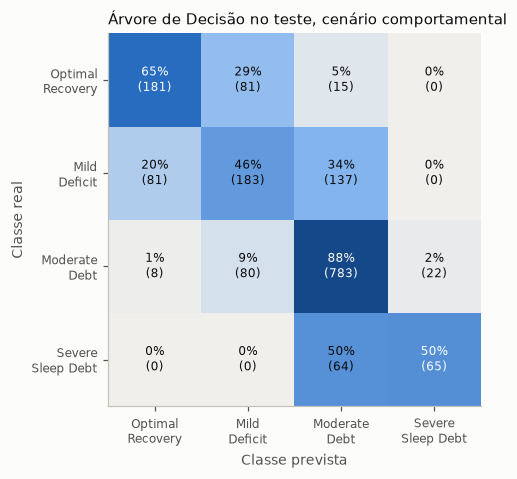

In [8]:
fig, ax = plt.subplots(figsize=(4.8, 4.4))
plot_confusion_matrix(y_test, previsoes["tree"], ax=ax)
ax.set_title("Árvore de Decisão no teste, cenário comportamental")
salvar(fig, "07_matriz_confusao_arvore")

**Resultado:**

- **`Moderate Debt`** é a classe mais bem reconhecida (F1 de 0,83 na árvore e 0,82 no Gaussiano), por ser a maior e a do meio da escala.
- **`Mild Deficit`** tem o menor F1 nos dois modelos (0,49 e 0,51) e a menor revocação na árvore (46%): fica entre `Optimal Recovery` e `Moderate Debt`, e os modelos erram para os dois lados.
- **A identificação dos casos de `Severe Sleep Debt` ainda é limitada:** a árvore encontra 50% dos casos graves, e 75% dos registros que ela prevê como graves realmente são. O Gaussiano encontra 48%, e 70% das previsões dele estão certas. Os casos não encontrados vão para `Moderate Debt`.
- **`Optimal Recovery`:** o Gaussiano encontra mais casos (69% × 65%).
- **Quase todos os erros ficam entre classes vizinhas:** 95% dos erros da árvore (465 de 488) são de um nível só. Nenhum registro de `Optimal Recovery` ou `Mild Deficit` é previsto como `Severe Sleep Debt`, nem o contrário; os poucos erros de dois níveis trocam `Optimal Recovery` por `Moderate Debt`.

## 3. Importância dos atributos

Duas medidas:

- **Importância da árvore** (redução da impureza de Gini): quanto cada atributo contribui para as divisões da árvore, calculada no treino. Com one-hot, cada categoria de uma nominal vira uma coluna, e as importâncias dessas colunas são somadas para dar a do atributo original.
- **Importância por permutação:** quanto o F1 macro no teste cai quando os valores de um atributo são embaralhados, quebrando a relação dele com o alvo (20 repetições). Funciona para qualquer modelo, então permite comparar a árvore com o Naive Bayes Gaussiano. O teste é usado só para medir, sem mudar nenhum modelo.

In [9]:
arvore = modelos_finais["tree"]
nomes_saida = arvore.named_steps["prep"].get_feature_names_out()
gini = pd.Series(arvore.named_steps["model"].feature_importances_, index=nomes_saida)
# Colunas one-hot (ex.: occupation_type_Student) somadas no atributo original
original = [next(c for c in colunas_cenario if nome == c or nome.startswith(f"{c}_")) for nome in nomes_saida]
importancia = gini.groupby(original).sum().to_frame("árvore (Gini)")

for nome in ["tree", "gaussian_nb"]:
    with ignore_bin_warnings():
        permutacao = permutation_importance(modelos_finais[nome], X_test[colunas_cenario], y_test, scoring="f1_macro",
                                            n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
    importancia[f"permutação: {MODEL_NAMES[nome]}"] = pd.Series(permutacao.importances_mean, index=colunas_cenario)
    importancia[f"dp: {MODEL_NAMES[nome]}"] = pd.Series(permutacao.importances_std, index=colunas_cenario)

importancia = importancia.sort_values("árvore (Gini)", ascending=False)
importancia.round(3)

,árvore (Gini),permutação: Árvore de Decisão,dp: Árvore de Decisão,permutação: Naive Bayes Gaussiano,dp: Naive Bayes Gaussiano
bedtime_phone_minutes,0.440,0.261,0.009,0.252,0.010
chronotype,0.369,0.244,0.010,0.195,0.006
occupation_type,0.150,0.052,0.004,0.047,0.007
caffeine_post_5pm_mg,0.016,0.003,0.004,0.005,0.008
screen_brightness_pct,0.012,0.009,0.005,0.009,0.005
blue_light_filter_active,0.006,-0.000,0.003,0.001,0.003
primary_bedtime_app,0.005,0.007,0.005,0.013,0.006
age,0.001,0.000,0.000,0.002,0.003
physical_activity_min,0.001,0.000,0.000,-0.001,0.003
gender,0.000,0.000,0.000,0.004,0.005


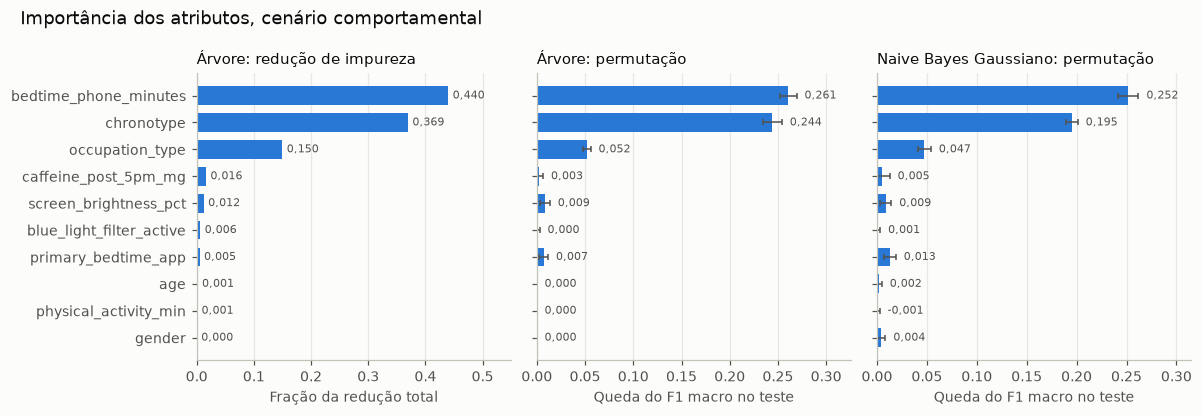

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(11, 3.8), sharey=True)
ordem = importancia.index[::-1]
cor = SCENARIO_COLORS["comportamental"]
paineis = [("árvore (Gini)", None, "Árvore: redução de impureza", "Fração da redução total"),
           ("permutação: Árvore de Decisão", "dp: Árvore de Decisão", "Árvore: permutação", "Queda do F1 macro no teste"),
           ("permutação: Naive Bayes Gaussiano", "dp: Naive Bayes Gaussiano", "Naive Bayes Gaussiano: permutação",
            "Queda do F1 macro no teste")]
for ax, (coluna, desvio, titulo, rotulo) in zip(eixos, paineis):
    valores = importancia.loc[ordem, coluna]
    erro = importancia.loc[ordem, desvio] if desvio else None
    ax.barh(ordem, valores.clip(lower=0), xerr=erro, color=cor, height=0.7,
            error_kw={"lw": 1, "capsize": 2, "ecolor": TEXTO_SECUNDARIO})
    for yi, (valor, dp) in enumerate(zip(valores, erro if erro is not None else np.zeros(len(valores)))):
        valor = 0.0 if abs(valor) < 5e-4 else valor  # evita "-0,000"
        ax.text(max(valor, 0) + dp + 0.008, yi, f"{valor:.3f}".replace(".", ","), va="center", fontsize=7.5,
                color=TEXTO_SECUNDARIO)
    ax.set_title(titulo)
    ax.set_xlabel(rotulo)
    ax.set_xlim(0, valores.max() * 1.25)
    ax.grid(axis="y", visible=False)
fig.suptitle("Importância dos atributos, cenário comportamental", x=0.02, ha="left")
fig.tight_layout()
salvar(fig, "07_importancia_atributos")

**Resultado:**

- **Dois atributos dominam: `bedtime_phone_minutes` (minutos de celular na cama) e `chronotype` (cronotipo).** Juntos, eles respondem por 81% da redução de impureza da árvore. Embaralhar qualquer um dos dois derruba o F1 macro em cerca de 0,2 a 0,26, nos dois modelos. É o que a EDA indicava.
- **`occupation_type`** vem em terceiro, bem atrás. Na árvore, toda a importância dele vem de uma única coluna one-hot, a dos profissionais de saúde e de turnos (`Healthcare / Shift Worker`), que têm muito mais débito severo que as outras ocupações (seção 4).
- **Os demais atributos contribuem pouco nestes modelos:** embaralhar cafeína, brilho da tela, aplicativo, filtro de luz azul, gênero, idade ou atividade física muda o F1 macro em no máximo 0,013. Isso descreve a contribuição deles para a previsão, nestes modelos e nesta base, quando o tempo de uso e o cronotipo já são conhecidos; não mostra que eles não têm efeito sobre o sono.
- **A árvore e o Naive Bayes Gaussiano concordam** na ordem dos três primeiros atributos, embora funcionem de formas muito diferentes. A importância por permutação é específica de cada modelo, mas a concordância entre dois modelos diferentes indica que esse resultado não é um detalhe de um deles.

### O KNN com menos atributos

A hipótese da seção 1 é que o KNN perde desempenho porque dá o mesmo peso, na distância, a atributos que pouco contribuem. Para testá-la, o KNN é ajustado de novo só com os três atributos de maior importância Gini (calculada no treino), com a mesma grade e os mesmos folds da etapa 6. A comparação usa só a validação cruzada no treino.

In [11]:
from scroll_sono.evaluation import cv_scores, grid_search, make_cv
from scroll_sono.models import PARAM_GRIDS

principais = importancia["árvore (Gini)"].nlargest(3).index.tolist()
busca_knn = grid_search(build_pipeline("knn", principais), PARAM_GRIDS["knn"], X_train, y_train, make_cv())
knn_reduzido = cv_scores(busca_knn)
pd.DataFrame({
    "atributos": [f"os {len(colunas_cenario)} do cenário comportamental", ", ".join(principais)],
    "F1 macro (validação cruzada)": [f"{melhores.loc['knn', 'cv_f1_macro']:.3f} ± {melhores.loc['knn', 'cv_f1_macro_dp']:.3f}",
                                     f"{knn_reduzido['cv_f1_macro']:.3f} ± {knn_reduzido['cv_f1_macro_dp']:.3f}"],
}, index=["KNN da etapa 6", "KNN com 3 atributos"])

,atributos,F1 macro (validação cruzada)
KNN da etapa 6,os 10 do cenário comportamental,0.578 ± 0.020
KNN com 3 atributos,"bedtime_phone_minutes, chronotype, occupation_...",0.638 ± 0.022


**Resultado:** com só os três atributos principais, o F1 macro do KNN na validação cruzada sobe de 0,578 para 0,638, perto da árvore e do Naive Bayes Gaussiano. O resultado apoia a hipótese de que os atributos pouco informativos atrapalham as distâncias. Ele serve de evidência, e não de modelo final: a escolha dos três atributos foi feita depois de ver os resultados da etapa 6, então esse KNN não é avaliado no teste. Além disso, os três atributos foram escolhidos pela árvore ajustada no treino inteiro, fora dos folds, então o valor não é uma estimativa independente do processo de seleção. Repetindo a seleção dentro de cada fold, os mesmos três atributos ficam no topo nos 10 folds.

## 4. Como o tempo de tela e o cronotipo se combinam

As primeiras divisões da árvore usam só esses dois atributos (cronotipo codificado como 0 = `Morning Lark`, 1 = `Intermediate`, 2 = `Night Owl`):

In [12]:
print(export_text(arvore.named_steps["model"], feature_names=list(nomes_saida), max_depth=2))

|--- chronotype <= 1.50
|   |--- bedtime_phone_minutes <= 59.50
|   |   |--- chronotype <= 0.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- chronotype >  0.50
|   |   |   |--- truncated branch of depth 4
|   |--- bedtime_phone_minutes >  59.50
|   |   |--- bedtime_phone_minutes <= 139.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- bedtime_phone_minutes >  139.50
|   |   |   |--- truncated branch of depth 4
|--- chronotype >  1.50
|   |--- bedtime_phone_minutes <= 105.50
|   |   |--- bedtime_phone_minutes <= 73.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- bedtime_phone_minutes >  73.50
|   |   |   |--- truncated branch of depth 4
|   |--- bedtime_phone_minutes >  105.50
|   |   |--- bedtime_phone_minutes <= 125.50
|   |   |   |--- truncated branch of depth 4
|   |   |--- bedtime_phone_minutes >  125.50
|   |   |   |--- truncated branch of depth 3



Para ver a relação sem o modelo, a tabela abaixo mostra, no **treino**, a proporção de cada classe extrema por cronotipo e faixa de minutos de celular na cama:

In [13]:
faixas = pd.cut(train["bedtime_phone_minutes"], [0, 30, 60, 90, 120, 180],
                labels=["até 30", "31 a 60", "61 a 90", "91 a 120", "121 a 180"], include_lowest=True)
cronotipos = ORDINAL_COLS["chronotype"]
agrupado = train.groupby([train["chronotype"], faixas], observed=True)[TARGET]

contagens = agrupado.size().unstack().loc[cronotipos]
extremos = {classe: (100 * agrupado.apply(lambda s, c=classe: (s == c).mean())).unstack().loc[cronotipos]
            for classe in ["Optimal Recovery", "Severe Sleep Debt"]}
pd.concat({"registros": contagens, **{f"% {c}": t.round(1) for c, t in extremos.items()}}, axis=1)

registros                                    % Optimal Recovery                           \
bedtime_phone_minutes    até 30 31 a 60 61 a 90 91 a 120 121 a 180             até 30 31 a 60 61 a 90 91 a 120   
chronotype                                                                                                       
Morning Lark                416     607     374      177       136               76.7    50.1    24.1      5.1   
Intermediate                738    1124     675      364       247               32.5    12.0     1.2      0.0   
Night Owl                   498     697     428      190       129                1.0     0.0     0.0      0.0   

                                % Severe Sleep Debt                                     
bedtime_phone_minutes 121 a 180              até 30 31 a 60 61 a 90 91 a 120 121 a 180  
chronotype                                                                              
Morning Lark                0.0                 0.0     0.0     0.3      2.8      29.4  
Intermediate                0.0                 0.0     0.0     2.2     11.8      53.4  
Night Owl                   0.0                 0.4     3.0    17.1     42.1      82.2

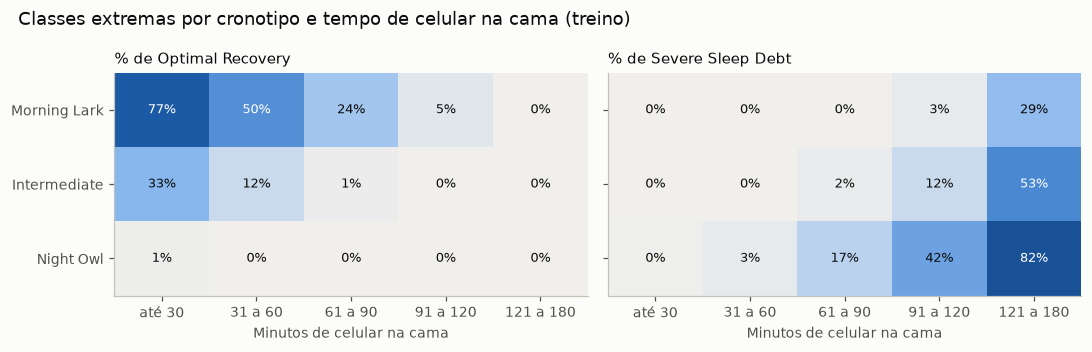

In [14]:
fig, eixos = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (classe, tabela_pct) in zip(eixos, extremos.items()):
    ax.imshow(tabela_pct, cmap=SEQUENTIAL, vmin=0, vmax=100, aspect="auto")
    for i in range(tabela_pct.shape[0]):
        for j in range(tabela_pct.shape[1]):
            valor = tabela_pct.iat[i, j]
            ax.text(j, i, f"{valor:.0f}%", ha="center", va="center", fontsize=8.5,
                    color="white" if valor > 50 else TEXTO)
    ax.set_xticks(range(tabela_pct.shape[1]), tabela_pct.columns)
    ax.set_yticks(range(len(cronotipos)), cronotipos)
    ax.set_xlabel("Minutos de celular na cama")
    ax.set_title(f"% de {classe}")
    ax.grid(False)
fig.suptitle("Classes extremas por cronotipo e tempo de celular na cama (treino)", x=0.02, ha="left")
fig.tight_layout()
salvar(fig, "07_tempo_de_tela_cronotipo")

In [15]:
ocupacao = (100 * pd.crosstab(train["occupation_type"], train[TARGET], normalize="index"))[TARGET_CLASSES]
ocupacao.round(1).sort_values("Severe Sleep Debt", ascending=False)

sleep_debt_category,Optimal Recovery,Mild Deficit,Moderate Debt,Severe Sleep Debt
occupation_type,,,,
Healthcare / Shift Worker,1.4,9.0,71.4,18.3
Freelance / Creative,15.9,24.9,51.9,7.3
Corporate 9-to-5,18.6,25.8,49.1,6.5
Student,18.8,26.6,48.7,5.9
Remote Tech,18.7,24.7,51.1,5.4


**Resultado:**

- **Mais tempo de celular na cama, mais débito de sono, em todos os cronotipos.** Entre os `Morning Lark` (matutinos), 77% dos que usam o celular por até 30 minutos têm sono reparador (`Optimal Recovery`); acima de 120 minutos, nenhum tem, e 29% chegam ao débito severo.
- **O cronotipo muda o ponto de partida.** Os `Night Owl` (vespertinos) quase nunca têm sono reparador, mesmo com pouco uso do celular (1% até 30 minutos), e acima de 120 minutos 82% deles estão em débito severo. Os `Intermediate` ficam entre os dois.
- **O tempo de tela e o cronotipo se somam.** O mesmo tempo de celular tem consequências diferentes conforme o cronotipo, por isso a árvore divide primeiro pelo cronotipo e depois pelos minutos de uso.
- **Profissionais de saúde e de turnos** têm 18% de débito severo e quase nenhum sono reparador, contra 5% a 7% de débito severo nas outras ocupações.
- A árvore final tem 6 níveis e 53 folhas, então não é lida como um todo; as primeiras divisões e a importância dos atributos resumem o que ela aprendeu.

## 5. Conclusões

**Os hábitos antes de dormir permitem prever a categoria de débito de sono?** Em parte.

- **Sim, bem acima do acaso.** Com os atributos de perfil e de antes de dormir, os melhores modelos (árvore de decisão e Naive Bayes Gaussiano, com desempenhos próximos) acertam cerca de 70% dos registros do teste e têm F1 macro de cerca de 0,64. O baseline, que sempre aposta na classe mais comum, acerta 52,5% e nunca reconhece as outras três classes.
- **Nos modelos avaliados, o que mais pesa é quanto tempo a pessoa fica no celular na cama e o cronotipo dela.** No treino, os registros de pessoas matutinas que usam pouco o celular quase sempre têm sono reparador, e os de pessoas vespertinas que passam mais de duas horas no celular estão, na maioria, em débito severo. A ocupação vem em seguida, por causa dos profissionais de saúde e de turnos.
- **Brilho da tela, filtro de luz azul, tipo de aplicativo e cafeína contribuem pouco** para a previsão nestes modelos, quando o tempo de uso e o cronotipo já são conhecidos.
- **Quase todos os erros são de um nível.** Os modelos confundem classes vizinhas (débito leve com moderado, por exemplo), mas não confundem quem dorme bem com quem está em débito severo.
- **A identificação do débito severo ainda é limitada:** a árvore encontra metade dos casos, e o resto aparece como débito moderado. O débito leve, entre o sono reparador e o débito moderado, é a classe com menos acertos na árvore.
- **As medidas do sono resolvem o problema, mas não servem para prever.** Com as horas de sono e a fadiga do dia seguinte (cenário completo), a árvore acerta 100%, porque o alvo é definido a partir delas. Essas informações só existem depois da noite de sono.

## 6. Limitações

- **Dados sintéticos.** A base foi gerada por uma simulação com regras definidas pelo autor. Os resultados mostram as relações que a simulação contém (por exemplo, o peso grande do cronotipo e o peso pequeno do filtro de luz azul nos modelos), não necessariamente o comportamento de pessoas reais.
- **Associação, não causa.** Os modelos mostram quais hábitos acompanham o débito de sono, não que mudar um hábito muda o sono. A importância dos atributos também é específica dos modelos avaliados.
- **Uma revisão depois do teste.** A codificação one-hot da árvore foi incluída depois de o teste já ter sido usado uma vez (com códigos inteiros, a árvore tinha F1 macro de 0,634 no teste). A opção foi escolhida só pela validação cruzada, mas, a rigor, o teste deixou de ser totalmente independente das decisões.
- **Investigação do vazamento na base inteira.** Os limites que reproduzem o alvo foram encontrados na etapa 1, antes da separação treino/teste. Isso não muda o cenário principal, cujas colunas foram escolhidas pelo momento da coleta, mas o mais rigoroso seria fazer essa investigação só no treino.
- **O alvo é uma regra sobre as horas de sono e a fadiga.** Os hábitos antes de dormir explicam só parte dessas medidas, o que limita o desempenho do cenário comportamental, principalmente no débito severo.
- **Uma única noite por pessoa.** Não há como acompanhar a mesma pessoa ao longo do tempo nem separar hábitos de um dia dos hábitos de costume.
- **Escolhas de modelagem:** os hiperparâmetros foram escolhidos pelo F1 macro. Um uso que priorize encontrar os casos graves poderia preferir outra métrica (por exemplo, a revocação de `Severe Sleep Debt`), com mais alarmes falsos em troca.

## Resumo

- **Tabela comparativa:** `reports/metrics/resultados.csv` e figura `07_comparacao_cenarios`. No cenário comportamental, árvore (F1 macro de 0,646 no teste) e Naive Bayes Gaussiano (0,637) com desempenhos próximos, cerca de 70% de acerto contra 52,5% do baseline. No completo, a árvore chega a 100% pelo vazamento.
- **Matriz de confusão da árvore:** `07_matriz_confusao_arvore`. 95% dos erros entre classes vizinhas; 50% dos casos de débito severo encontrados; `Mild Deficit` é a classe com menos acertos.
- **Importância dos atributos:** `07_importancia_atributos`. Minutos de celular na cama e cronotipo dominam, nos dois modelos; ocupação em terceiro. Com só esses três atributos, o KNN sobe de 0,578 para 0,638 de F1 macro na validação cruzada.
- **Relação entre os dois principais atributos:** `07_tempo_de_tela_cronotipo`.
- **Conclusão:** os hábitos antes de dormir preveem o débito de sono bem acima do acaso, principalmente pelo tempo de celular na cama combinado com o cronotipo, mas não bastam para identificar com segurança o débito severo. Os dados são sintéticos.